# ============================================
# 01_eda.ipynb — Exploratory Data Analysis
# IT3091 ML Assignment — Ames Housing Dataset
# ============================================

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score

In [2]:
# --- Load raw data ---
from google.colab import files
uploaded = files.upload()  # upload train.csv

train = pd.read_csv('train.csv')
print("Train shape:", train.shape)
train.head()

Saving train.csv to train.csv
Train shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


# --- Data dictionary overview ---

In [3]:
print(train.dtypes.value_counts())
print("\nColumn list:")
print(train.columns.tolist())

object     43
int64      35
float64     3
Name: count, dtype: int64

Column list:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF'

# --- Target variable: SalePrice distribution ---

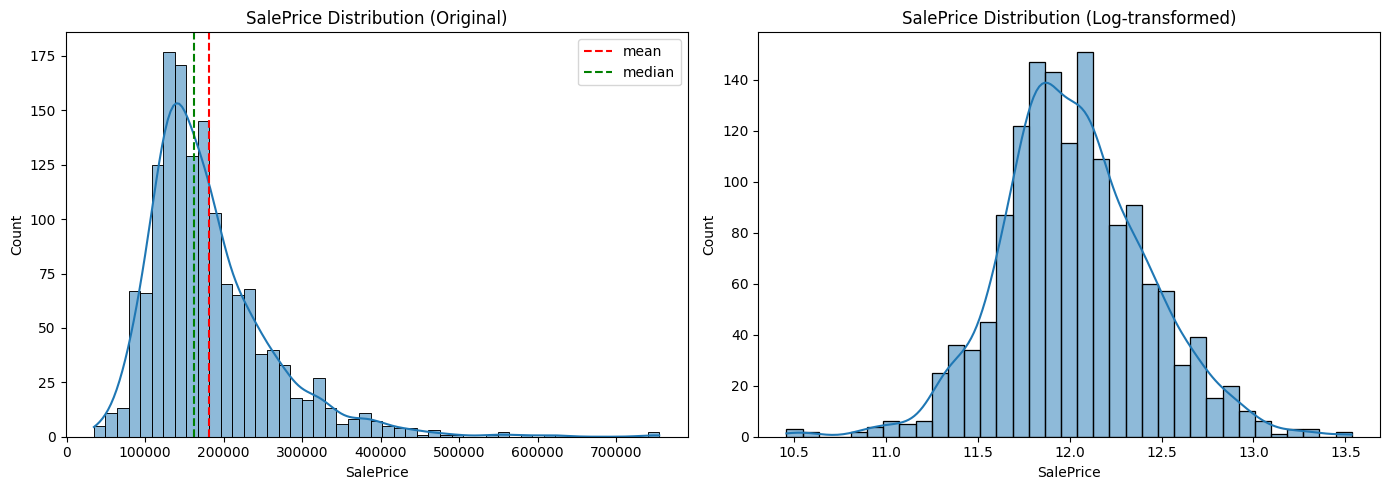

Skewness (original): 1.8828757597682129
Skewness (log-transformed): 0.12134661989685333

Summary stats:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(train['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('SalePrice Distribution (Original)')
axes[0].axvline(train['SalePrice'].mean(), color='red', linestyle='--', label='mean')
axes[0].axvline(train['SalePrice'].median(), color='green', linestyle='--', label='median')
axes[0].legend()

sns.histplot(np.log1p(train['SalePrice']), kde=True, ax=axes[1])
axes[1].set_title('SalePrice Distribution (Log-transformed)')

plt.tight_layout()
plt.show()

print("Skewness (original):", train['SalePrice'].skew())
print("Skewness (log-transformed):", np.log1p(train['SalePrice']).skew())
print("\nSummary stats:")
print(train['SalePrice'].describe())

# --- Missing value analysis ---

              Missing Count  Missing %
PoolQC                 1453      99.52
MiscFeature            1406      96.30
Alley                  1369      93.77
Fence                  1179      80.75
MasVnrType              872      59.73
FireplaceQu             690      47.26
LotFrontage             259      17.74
GarageType               81       5.55
GarageYrBlt              81       5.55
GarageFinish             81       5.55
GarageQual               81       5.55
GarageCond               81       5.55
BsmtExposure             38       2.60
BsmtFinType2             38       2.60
BsmtQual                 37       2.53
BsmtCond                 37       2.53
BsmtFinType1             37       2.53
MasVnrArea                8       0.55
Electrical                1       0.07


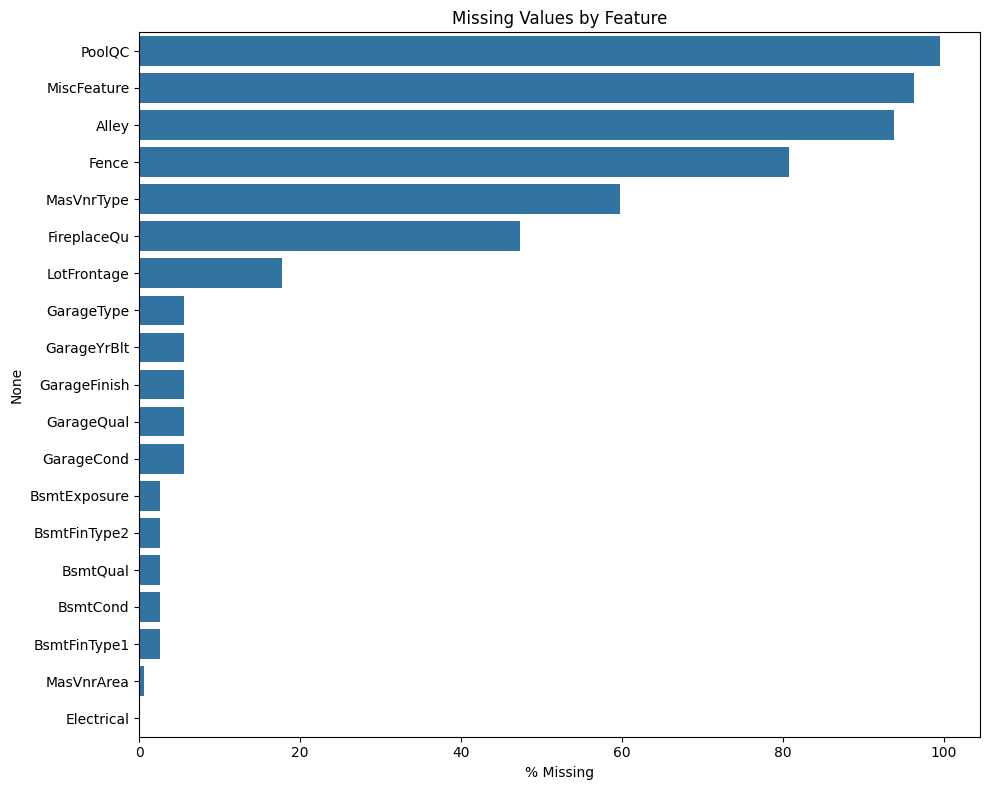

In [5]:
missing = train.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_pct = (missing / len(train)) * 100

missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct.round(2)})
print(missing_df)

plt.figure(figsize=(10, 8))
sns.barplot(x=missing_pct.values, y=missing_pct.index)
plt.xlabel('% Missing')
plt.title('Missing Values by Feature')
plt.tight_layout()
plt.show()

# --- Correlation of key numeric features with SalePrice ---

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64


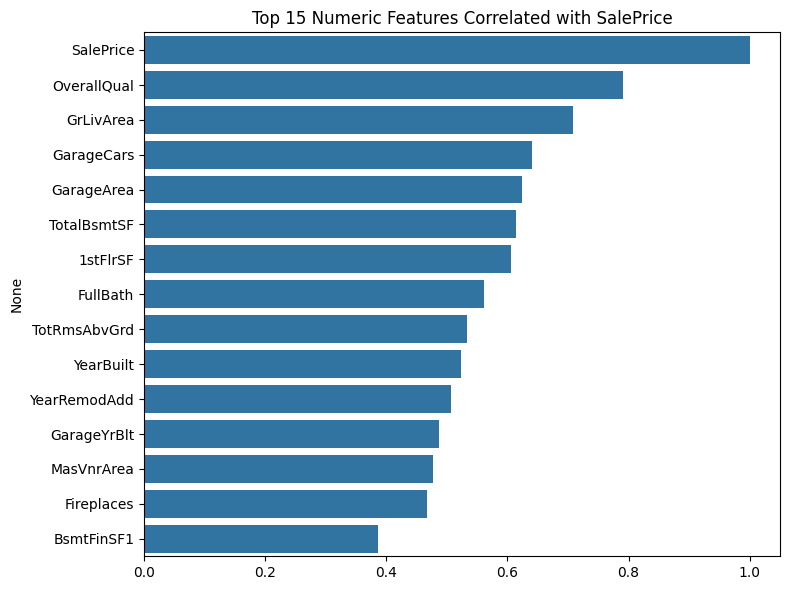

In [6]:
numeric_cols = train.select_dtypes(include=[np.number]).columns
top_corr = train[numeric_cols].corr()['SalePrice'].sort_values(ascending=False).head(15)
print(top_corr)

plt.figure(figsize=(8, 6))
sns.barplot(x=top_corr.values, y=top_corr.index)
plt.title('Top 15 Numeric Features Correlated with SalePrice')
plt.tight_layout()
plt.show()

# ============================================
# 02_preprocessing.ipynb — Cleaning, Encoding, Feature Engineering
# IT3091 ML Assignment — Ames Housing Dataset
# ============================================

# --- Step 1: Handle missing values ---

In [7]:
# Structural "None" categoricals (NaN means the feature doesn't exist)
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtExposure', 'BsmtFinType2', 'BsmtQual', 'BsmtCond', 'BsmtFinType1',
             'MasVnrType']
for col in none_cols:
    train[col] = train[col].fillna('None')

# Structural zero numerics
train['GarageYrBlt'] = train['GarageYrBlt'].fillna(0)
train['MasVnrArea'] = train['MasVnrArea'].fillna(0)

# Genuine missing: LotFrontage by neighborhood median
train['LotFrontage'] = train.groupby('Neighborhood')['LotFrontage'].transform(
    lambda x: x.fillna(x.median())
)

# Electrical: single missing row, impute with mode
train['Electrical'] = train['Electrical'].fillna(train['Electrical'].mode()[0])

print("Remaining missing values:", train.isnull().sum().sum())

Remaining missing values: 0


# --- Step 2: Feature engineering ---

LogSalePrice    1.000000
TotalSF         0.777297
TotalBath       0.673011
HasFireplace    0.510026
HasGarage       0.322998
RemodAge       -0.568136
HouseAge       -0.587290
Name: LogSalePrice, dtype: float64


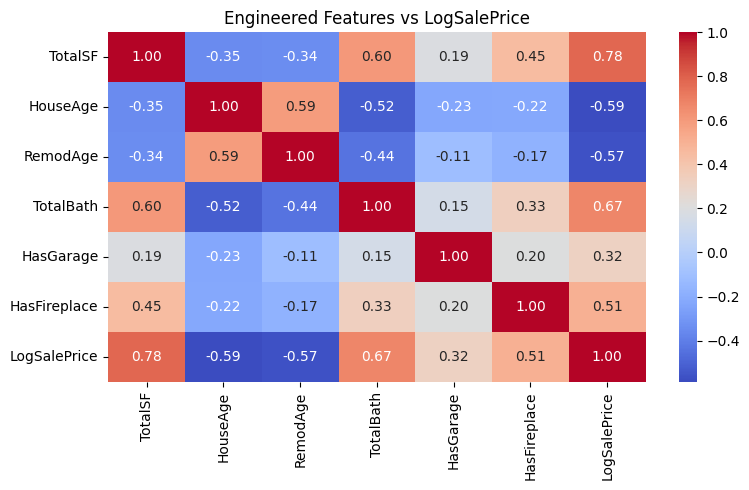

In [8]:
train['TotalSF'] = train['TotalBsmtSF'] + train['1stFlrSF'] + train['2ndFlrSF']
train['HouseAge'] = train['YrSold'] - train['YearBuilt']
train['RemodAge'] = train['YrSold'] - train['YearRemodAdd']
train['TotalBath'] = (train['FullBath'] + 0.5 * train['HalfBath'] +
                       train['BsmtFullBath'] + 0.5 * train['BsmtHalfBath'])
train['HasGarage'] = (train['GarageArea'] > 0).astype(int)
train['HasFireplace'] = (train['Fireplaces'] > 0).astype(int)
# Note: HasPool dropped - correlation with target was ~0.07, negligible (see EDA)

train['LogSalePrice'] = np.log1p(train['SalePrice'])

new_features = ['TotalSF', 'HouseAge', 'RemodAge', 'TotalBath', 'HasGarage', 'HasFireplace']
corr = train[new_features + ['LogSalePrice']].corr()['LogSalePrice'].sort_values(ascending=False)
print(corr)

plt.figure(figsize=(8, 5))
sns.heatmap(train[new_features + ['LogSalePrice']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Engineered Features vs LogSalePrice')
plt.tight_layout()
plt.show()

# --- Step 3: Encode categorical variables ---

In [9]:
# Ordinal quality/condition columns (shared scale: Po < Fa < TA < Gd < Ex)
qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
ordinal_qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
                     'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']
for col in ordinal_qual_cols:
    train[col] = train[col].map(qual_map)

# Other ordinal columns with their own scales
train['BsmtExposure'] = train['BsmtExposure'].map({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4})
train['BsmtFinType1'] = train['BsmtFinType1'].map({'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6})
train['BsmtFinType2'] = train['BsmtFinType2'].map({'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6})
train['GarageFinish'] = train['GarageFinish'].map({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3})

# Remaining categorical columns are nominal -> one-hot encode
remaining_cat_cols = train.select_dtypes(include='object').columns.tolist()
print("Nominal columns to one-hot encode:", len(remaining_cat_cols))

train_encoded = pd.get_dummies(train, columns=remaining_cat_cols, drop_first=True)
print("Shape before encoding:", train.shape)
print("Shape after one-hot encoding:", train_encoded.shape)

Nominal columns to one-hot encode: 30
Shape before encoding: (1460, 88)
Shape after one-hot encoding: (1460, 225)


# --- Step 4: Save processed data ---

In [11]:
train_encoded.to_csv('processed_train.csv', index=False)
print("Saved processed_train.csv - shape:", train_encoded.shape)

from google.colab import files
files.download('processed_train.csv')

Saved processed_train.csv - shape: (1460, 225)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# ============================================
# 03_modeling.ipynb — Baseline + Alternative Models
# IT3091 ML Assignment — Ames Housing Dataset
# ============================================

In [12]:
# --- Load processed data (standalone - output of 02_preprocessing.ipynb) ---
from google.colab import files
uploaded = files.upload()  # upload processed_train.csv

train_encoded = pd.read_csv('processed_train.csv')
print("Loaded shape:", train_encoded.shape)

Saving processed_train.csv to processed_train (1).csv
Loaded shape: (1460, 225)


# --- Prepare feature matrix and target ---

In [13]:
drop_cols = ['Id', 'SalePrice', 'LogSalePrice']
X = train_encoded.drop(columns=drop_cols)
y = train_encoded['LogSalePrice']

print("Feature matrix:", X.shape)
print("Any NaNs left?", X.isnull().sum().sum())

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train:", X_train.shape, "| X_val:", X_val.shape)

Feature matrix: (1460, 222)
Any NaNs left? 0
X_train: (1168, 222) | X_val: (292, 222)


# --- Helper: evaluation function (reused for every model) ---

In [14]:
def evaluate(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name}: RMSE={rmse:.4f} | MAE={mae:.4f} | R²={r2:.4f}")
    return rmse, mae, r2

# --- Baseline: Linear Regression (needs scaled features) ---

Linear Regression (baseline): RMSE=0.1548 | MAE=0.0937 | R²=0.8715


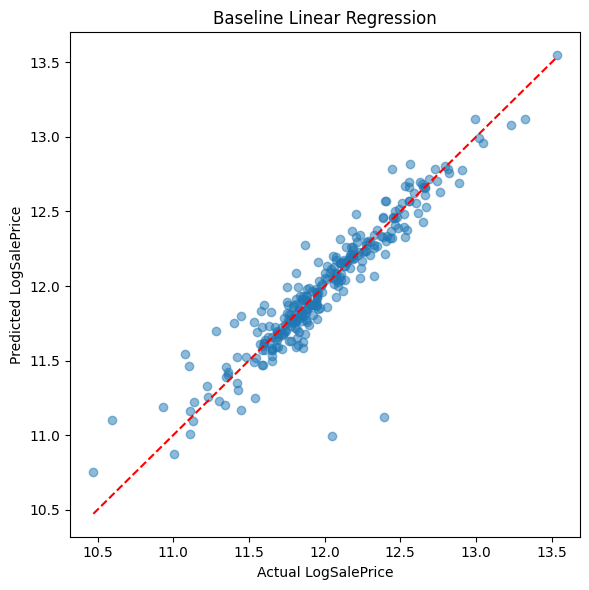

In [15]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_val_scaled)
evaluate("Linear Regression (baseline)", y_val, y_pred_lr)

plt.figure(figsize=(6, 6))
plt.scatter(y_val, y_pred_lr, alpha=0.5)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--')
plt.xlabel('Actual LogSalePrice'); plt.ylabel('Predicted LogSalePrice')
plt.title('Baseline Linear Regression'); plt.tight_layout(); plt.show()

# --- Ridge and Lasso (regularized linear models) ---

In [16]:
ridge = Ridge(alpha=10)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_val_scaled)

lasso = Lasso(alpha=0.001, max_iter=10000)  # max_iter raised to fix convergence warning
lasso.fit(X_train_scaled, y_train)
y_pred_lasso = lasso.predict(X_val_scaled)

evaluate("Ridge", y_val, y_pred_ridge)
evaluate("Lasso", y_val, y_pred_lasso)
print("Lasso zeroed out", np.sum(lasso.coef_ == 0), "of", len(lasso.coef_), "features")

Ridge: RMSE=0.1546 | MAE=0.0957 | R²=0.8719
Lasso: RMSE=0.1563 | MAE=0.0933 | R²=0.8690
Lasso zeroed out 61 of 222 features


# --- Random Forest and Gradient Boosting (tree-based, no scaling needed) ---

--- Full comparison ---
Linear Regression: RMSE=0.1548 | MAE=0.0937 | R²=0.8715
Ridge: RMSE=0.1546 | MAE=0.0957 | R²=0.8719
Lasso: RMSE=0.1563 | MAE=0.0933 | R²=0.8690
Random Forest: RMSE=0.1469 | MAE=0.0970 | R²=0.8843
Gradient Boosting: RMSE=0.1385 | MAE=0.0893 | R²=0.8973


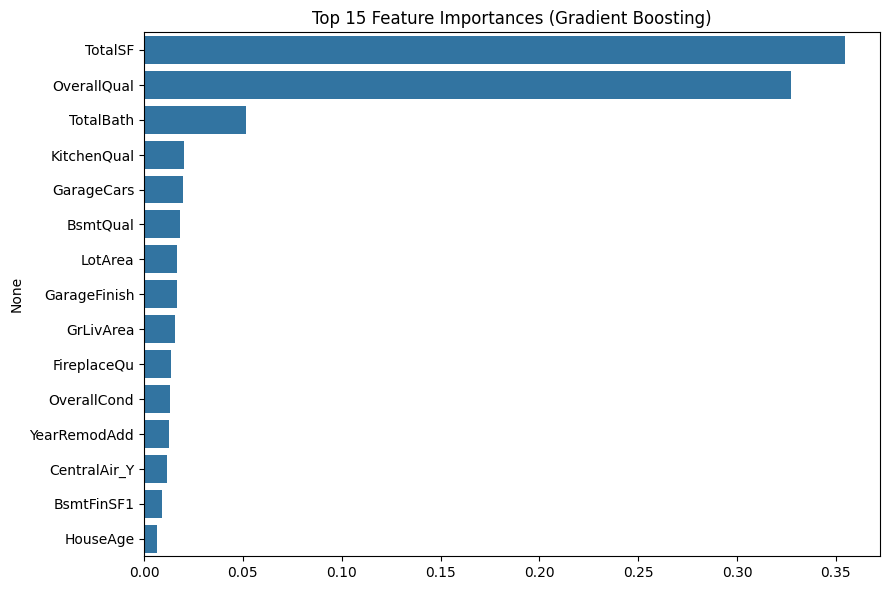

In [17]:
rf = RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_val)

gb = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=42)
gb.fit(X_train, y_train)
y_pred_gb = gb.predict(X_val)

print("--- Full comparison ---")
evaluate("Linear Regression", y_val, y_pred_lr)
evaluate("Ridge", y_val, y_pred_ridge)
evaluate("Lasso", y_val, y_pred_lasso)
evaluate("Random Forest", y_val, y_pred_rf)
evaluate("Gradient Boosting", y_val, y_pred_gb)

importances = pd.Series(gb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
plt.figure(figsize=(9, 6))
sns.barplot(x=importances.values, y=importances.index)
plt.title('Top 15 Feature Importances (Gradient Boosting)')
plt.tight_layout(); plt.show()

#---Compares all five models on the same validation set using RMSE, MAE and R²---

            Model  RMSE (log)  MAE (log)     R2
Linear (baseline)      0.1548     0.0937 0.8715
            Ridge      0.1546     0.0957 0.8719
            Lasso      0.1563     0.0933 0.8690
    Random Forest      0.1469     0.0970 0.8843
Gradient Boosting      0.1385     0.0893 0.8973


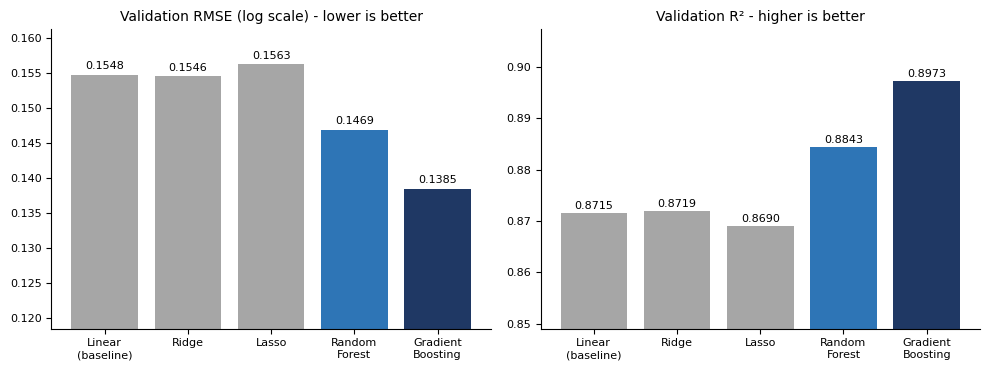

In [18]:
# --- Figure 7: Model comparison table + chart ---
preds = {
    'Linear\n(baseline)': y_pred_lr,
    'Ridge': y_pred_ridge,
    'Lasso': y_pred_lasso,
    'Random\nForest': y_pred_rf,
    'Gradient\nBoosting': y_pred_gb,
}

rows = []
for name, pred in preds.items():
    rows.append({
        'Model': name.replace('\n', ' '),
        'RMSE (log)': np.sqrt(mean_squared_error(y_val, pred)),
        'MAE (log)': mean_absolute_error(y_val, pred),
        'R2': r2_score(y_val, pred),
    })
results_df = pd.DataFrame(rows).round(4)
print(results_df.to_string(index=False))   # this is Table 7

colors = ['#A6A6A6', '#A6A6A6', '#A6A6A6', '#2E75B6', '#1F3864']
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))

bars = ax[0].bar(list(preds.keys()), results_df['RMSE (log)'], color=colors)
ax[0].set_title('Validation RMSE (log scale) - lower is better', fontsize=10)
ax[0].set_ylim(results_df['RMSE (log)'].min() - 0.02, results_df['RMSE (log)'].max() + 0.005)
for b, v in zip(bars, results_df['RMSE (log)']):
    ax[0].text(b.get_x() + b.get_width()/2, v + 0.0008, f"{v:.4f}", ha='center', fontsize=8)

bars = ax[1].bar(list(preds.keys()), results_df['R2'], color=colors)
ax[1].set_title('Validation R² - higher is better', fontsize=10)
ax[1].set_ylim(results_df['R2'].min() - 0.02, results_df['R2'].max() + 0.01)
for b, v in zip(bars, results_df['R2']):
    ax[1].text(b.get_x() + b.get_width()/2, v + 0.0008, f"{v:.4f}", ha='center', fontsize=8)

for a in ax:
    a.tick_params(labelsize=8)
    a.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('fig7_model_comparison.png', dpi=200)
plt.show()

# ---Checks that the result is not a lucky split. Lower RMSE is better.---

Gradient Boosting per fold: [0.1191 0.1351 0.1326 0.1183 0.1277] | mean 0.1265 | std 0.0069
Random Forest per fold:     [0.1349 0.1532 0.1434 0.1317 0.1515] | mean 0.143 | std 0.0086


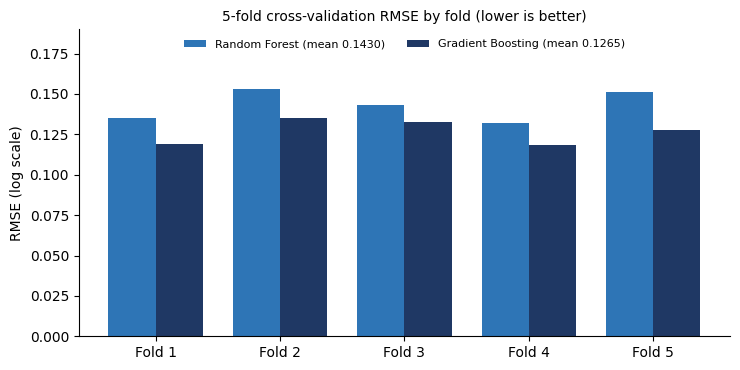

In [19]:
# --- Figure 8: 5-fold CV, Gradient Boosting vs Random Forest ---
from sklearn.model_selection import cross_val_score
from sklearn.impute import SimpleImputer

# Impute NaNs in the full feature matrix X
imputer = SimpleImputer(strategy='constant', fill_value=0)
X_clean = imputer.fit_transform(X)

cv_gb = -cross_val_score(gb, X_clean, y, cv=5, scoring='neg_root_mean_squared_error')
cv_rf = -cross_val_score(rf, X_clean, y, cv=5, scoring='neg_root_mean_squared_error')

print("Gradient Boosting per fold:", cv_gb.round(4), "| mean", cv_gb.mean().round(4), "| std", cv_gb.std().round(4))
print("Random Forest per fold:    ", cv_rf.round(4), "| mean", cv_rf.mean().round(4), "| std", cv_rf.std().round(4))

x = np.arange(5)
w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.bar(x - w/2, cv_rf, w, label=f"Random Forest (mean {cv_rf.mean():.4f})", color='#2E75B6')
ax.bar(x + w/2, cv_gb, w, label=f"Gradient Boosting (mean {cv_gb.mean():.4f})", color='#1F3864')
ax.set_xticks(x)
ax.set_xticklabels([f"Fold {i+1}" for i in range(5)])
ax.set_ylabel('RMSE (log scale)')
ax.set_title('5-fold cross-validation RMSE by fold (lower is better)', fontsize=10)
ax.set_ylim(0, 0.19)   # adds empty space at the top
ax.legend(fontsize=8, frameon=False, loc='upper center', ncol=2)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('fig8_cv_per_fold.png', dpi=200)
plt.show()

# --- Hyperparameter tuning on the best model (Gradient Boosting) ---

In [20]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [200, 300, 500],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4, 5],
    'subsample': [0.7, 0.85, 1.0]
}

search = RandomizedSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_distributions=param_dist,
    n_iter=20, cv=5, scoring='neg_root_mean_squared_error',
    random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV RMSE:", -search.best_score_)

best_gb = search.best_estimator_
y_pred_best = best_gb.predict(X_val)
evaluate("Tuned Gradient Boosting", y_val, y_pred_best)

Best params: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.03}
Best CV RMSE: 0.12759972945910528
Tuned Gradient Boosting: RMSE=0.1322 | MAE=0.0850 | R²=0.9063


(np.float64(0.13224088649857021), 0.08497988446449398, 0.9062881977414505)

# --- Save the final model + val data for 04_evaluation.ipynb ---

In [21]:
import joblib
joblib.dump(best_gb, 'best_gb_model.pkl')

X_val.to_csv('X_val.csv', index=False)
y_val.to_csv('y_val.csv', index=False)

from google.colab import files
files.download('best_gb_model.pkl')
files.download('X_val.csv')
files.download('y_val.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# ============================================
# 04_evaluation.ipynb — Metrics, Validation, Final Comparison
# IT3091 ML Assignment — Ames Housing Dataset
# ============================================

In [22]:
# --- Load saved model + validation data (standalone - output of 03_modeling.ipynb) ---
from google.colab import files
uploaded = files.upload()  # upload best_gb_model.pkl, X_val.csv, y_val.csv (all three)

best_gb = joblib.load('best_gb_model.pkl')
X_val = pd.read_csv('X_val.csv')
y_val = pd.read_csv('y_val.csv').squeeze()  # squeeze back to a Series

print("Model loaded:", best_gb)
print("X_val shape:", X_val.shape)

Saving y_val.csv to y_val (1).csv
Saving X_val.csv to X_val (1).csv
Saving best_gb_model.pkl to best_gb_model (1).pkl
Model loaded: GradientBoostingRegressor(learning_rate=0.03, n_estimators=500, random_state=42,
                          subsample=0.7)
X_val shape: (292, 222)


In [23]:
# --- Also need processed_train.csv to rebuild X_train/y_train for cross-validation ---
uploaded2 = files.upload()  # upload processed_train.csv

train_encoded = pd.read_csv('processed_train.csv')
drop_cols = ['Id', 'SalePrice', 'LogSalePrice']
X = train_encoded.drop(columns=drop_cols)
y = train_encoded['LogSalePrice']
print("Full feature matrix for CV:", X.shape)

Saving processed_train.csv to processed_train (2).csv
Full feature matrix for CV: (1460, 222)


# --- Final validation-set metrics ---

Tuned Gradient Boosting - Final Validation Metrics:
RMSE (log scale): 0.1322
MAE (log scale):  0.0850
R²:               0.9063
RMSE (dollars):   $28,275.59


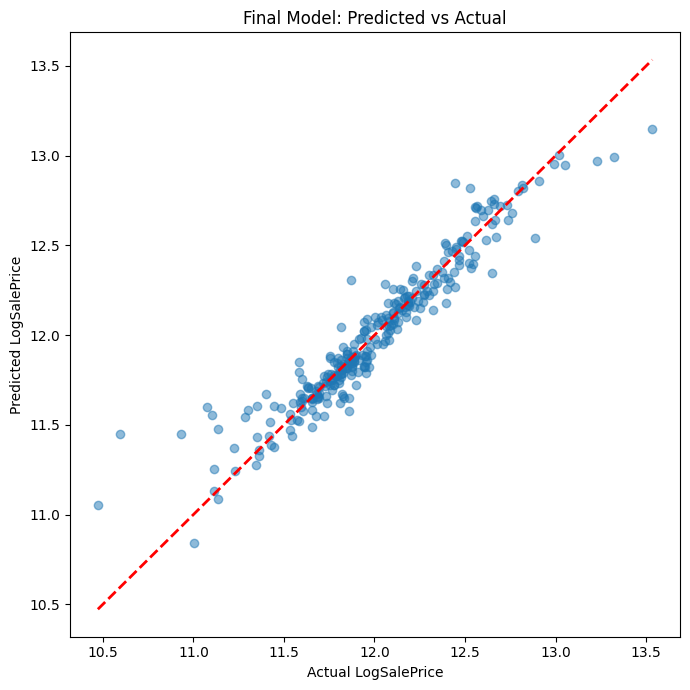

In [24]:
y_pred_best = best_gb.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, y_pred_best))
mae = mean_absolute_error(y_val, y_pred_best)
r2 = r2_score(y_val, y_pred_best)
rmse_dollars = np.sqrt(mean_squared_error(np.expm1(y_val), np.expm1(y_pred_best)))

print(f"Tuned Gradient Boosting - Final Validation Metrics:")
print(f"RMSE (log scale): {rmse:.4f}")
print(f"MAE (log scale):  {mae:.4f}")
print(f"R²:               {r2:.4f}")
print(f"RMSE (dollars):   ${rmse_dollars:,.2f}")

plt.figure(figsize=(7, 7))
plt.scatter(y_val, y_pred_best, alpha=0.5)
plt.plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2)
plt.xlabel('Actual LogSalePrice'); plt.ylabel('Predicted LogSalePrice')
plt.title('Final Model: Predicted vs Actual'); plt.tight_layout(); plt.show()

# --- 5-fold cross-validation (confirms result isn't a lucky split) ---


CV RMSE per fold: [0.1152 0.1358 0.1302 0.1127 0.131 ]
Mean CV RMSE: 0.1250 (+/- 0.0092)


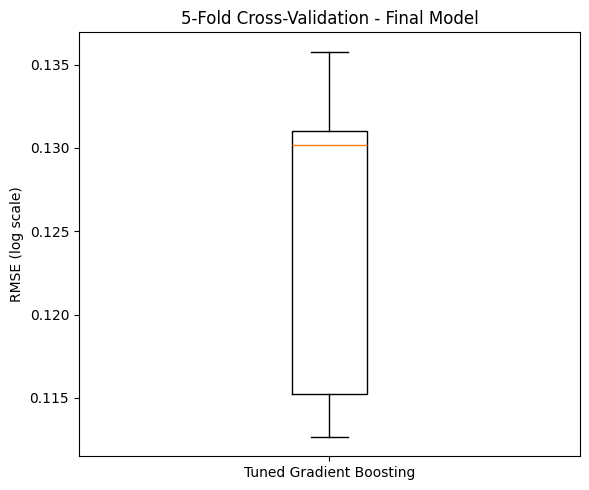

In [25]:
cv_scores = -cross_val_score(best_gb, X, y, cv=5, scoring='neg_root_mean_squared_error')

print("CV RMSE per fold:", cv_scores.round(4))
print(f"Mean CV RMSE: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")

plt.figure(figsize=(6, 5))
plt.boxplot(cv_scores, tick_labels=['Tuned Gradient Boosting'])
plt.ylabel('RMSE (log scale)')
plt.title('5-Fold Cross-Validation - Final Model')
plt.tight_layout(); plt.show()

# --- Residual analysis (checks for systematic errors / leakage) ---

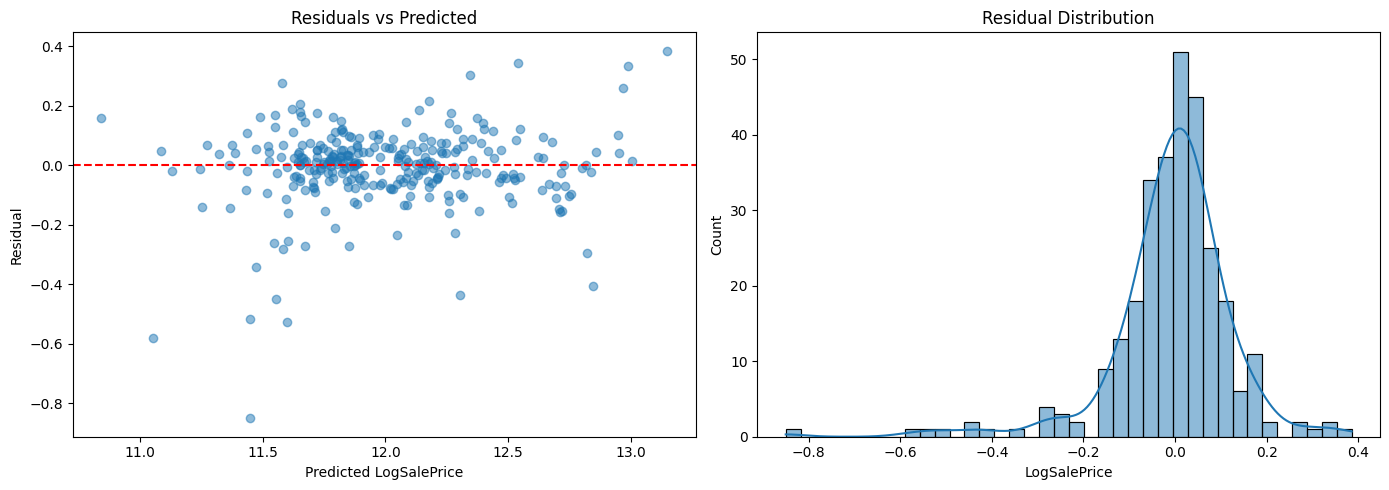

Residual mean: -0.006151219284962151
Residual std: 0.13232452365958147


In [26]:
residuals = y_val - y_pred_best

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.scatter(y_pred_best, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted LogSalePrice'); plt.ylabel('Residual')
plt.title('Residuals vs Predicted')

plt.subplot(1, 2, 2)
sns.histplot(residuals, kde=True)
plt.title('Residual Distribution')
plt.tight_layout(); plt.show()

print("Residual mean:", residuals.mean())
print("Residual std:", residuals.std())

# --- Feature importance (final interpretation for recommendation) ---

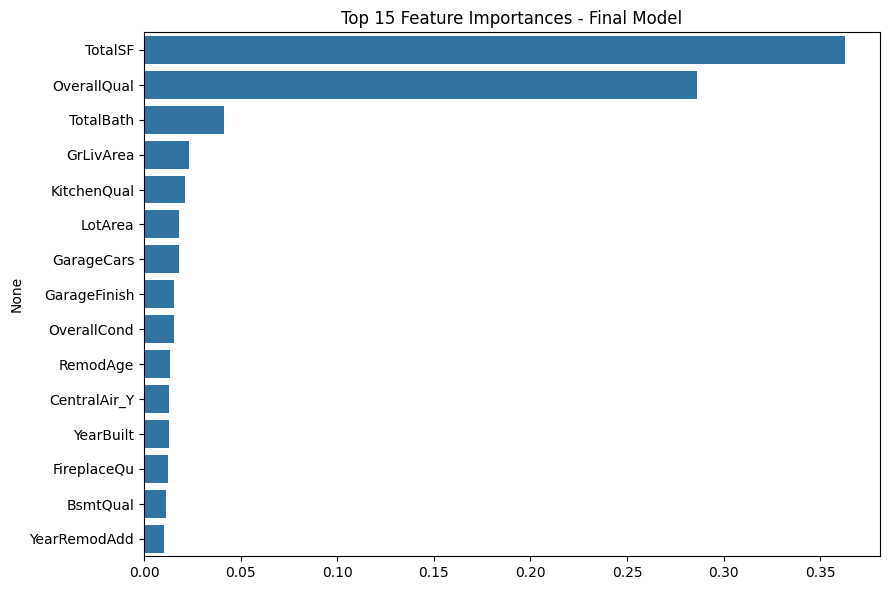

TotalSF         0.362826
OverallQual     0.286334
TotalBath       0.041171
GrLivArea       0.023332
KitchenQual     0.020984
LotArea         0.018099
GarageCars      0.017965
GarageFinish    0.015716
OverallCond     0.015257
RemodAge        0.013389
CentralAir_Y    0.013118
YearBuilt       0.013111
FireplaceQu     0.012187
BsmtQual        0.011560
YearRemodAdd    0.010324
dtype: float64


In [27]:
importances = pd.Series(best_gb.feature_importances_, index=X_val.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=importances.values, y=importances.index)
plt.title('Top 15 Feature Importances - Final Model')
plt.tight_layout(); plt.show()

print(importances)